# ShockGraph PEA: demo

This notebook goes through the project once, on the dev database (`make seed`, then C1 betas and C3 predictions).

1. Connection and what the graph holds
2. A shock on a student-style PEA: a world ETF (CW8-like) and three stocks
3. Graph Data Science: PageRank, Louvain communities, FastRP neighbours
4. A subgraph drawing around one company
5. Machine learning: the model against a simple baseline
6. One question to the agent, with its trace

Every number shown carries its **truth level**: `fact` (from a source), `estimate` (a regression on past prices),
`prediction` (the ML model), `hypothesis` (a news claim). Nothing here is investment advice.

## 1. Connection

The password comes from `.env` through `get_settings()`; it is never printed.

In [1]:
import json
import logging
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from app.config import get_settings
from app.database.neo4j import Neo4jClient
from app.models.common import DISCLAIMER

%config InlineBackend.figure_formats = ["svg"]
pd.set_option("display.max_colwidth", 60)
logging.getLogger("neo4j").setLevel(logging.ERROR)  # hide the driver's deprecation notices
settings = get_settings()
client = Neo4jClient.from_settings(settings)
print("connected to", settings.neo4j_uri)

connected to bolt://localhost:7687


In [2]:
labels = client.read(
    "MATCH (node) UNWIND labels(node) AS label RETURN label, count(*) AS nodes ORDER BY nodes DESC LIMIT 20"
)
relations = client.read(
    "MATCH ()-[rel]->() RETURN type(rel) AS relation, count(*) AS links ORDER BY links DESC LIMIT 20"
)
display(pd.DataFrame(labels), pd.DataFrame(relations))

,label,nodes
0,Company,2466
1,Industry,76
2,Country,66
3,Fund,14
4,Sector,12
5,Factor,12
6,Index,7
7,Commodity,7
8,Currency,3
9,Rate,2


,relation,links
0,CONSTITUENT,5658
1,CORRELATED_WITH,3818
2,SENSITIVE_TO,3579
3,IN_INDUSTRY,2466
4,HEADQUARTERED_IN,2466
5,PREDICTED_SENSITIVITY,676
6,PRODUCES,90
7,PART_OF,76
8,CONSUMES,29
9,TRACKS,14


`SENSITIVE_TO` (C1) is an **estimate**: an OLS regression of weekly stock returns on the factor, with the market
return as a control, kept only when it is significant. `CORRELATED_WITH` links stocks whose residual returns
move together. `PREDICTED_SENSITIVITY` (C3) is a **prediction** of the ML model.

## 2. A shock on a student-style PEA

4,000 EUR in Amundi PEA Monde (the CW8 ETF, MSCI World) and 1,000 EUR each in TotalEnergies, Airbus and BNP Paribas.
The look-through follows `Fund -TRACKS-> Index -CONSTITUENT-> Company`, so the ETF counts as its index weights.

In [3]:
from app.models.portfolio import PortfolioRequest
from app.services.portfolio import PortfolioService

POSITIONS = [
    {"isin": "FR0011869353", "amount_eur": 4000.0},  # Amundi PEA Monde (MSCI World), CW8
    {"isin": "FR0000120271", "amount_eur": 1000.0},  # TotalEnergies
    {"isin": "NL0000235190", "amount_eur": 1000.0},  # Airbus
    {"isin": "FR0000131104", "amount_eur": 1000.0},  # BNP Paribas
]
xray = PortfolioService(client).xray(PortfolioRequest(positions=POSITIONS))
print("total:", xray.total_eur, "EUR |", *xray.warnings)
display(
    pd.DataFrame([line.model_dump() for line in xray.companies]).sort_values("weight", ascending=False).head(8),
    pd.DataFrame([line.model_dump() for line in xray.sectors]).sort_values("weight", ascending=False).head(6),
    pd.DataFrame([line.model_dump() for line in xray.factors]).sort_values("factor_code"),
)

total: 7000.0 EUR | Synthetic fund FR0011869353 uses tracked index constituents; its physical HOLDS basket is ignored.


,key,label,amount_eur,weight
0,FR0000120271,TotalEnergies SE,1008.16400,0.144023
1,NL0000235190,Airbus SE,1005.82176,0.143689
2,FR0000131104,BNP Paribas S.A. Class A,1004.23624,0.143462
3,US0378331005,Apple Inc.,223.61680,0.031945
4,US67066G1040,NVIDIA Corporation,220.01700,0.031431
5,US5949181045,Microsoft Corporation,166.48144,0.023783
6,US0231351067,Amazon.com Inc.,106.79172,0.015256
7,US02079K3059,Alphabet Inc. Class A,82.78148,0.011826


,key,label,amount_eur,weight
0,FINANCIALS,Financials,1633.52844,0.233361
1,INDUSTRIALS,Industrials,1427.68084,0.203954
2,INFORMATION_TECHNOLOGY,Information Technology,1222.02588,0.174575
3,ENERGY,Energy,1182.00172,0.168857
4,HEALTH_CARE,Health Care,391.60324,0.055943
5,CONSUMER_DISCRETIONARY,Consumer Discretionary,344.36416,0.049195


,factor_code,weighted_beta,covered_weight
0,ALUMINIUM,0.000048,0.001111
1,BRENT,0.063956,0.169374
2,COPPER,0.001462,0.003321
3,EUR10Y,-0.086219,0.014543
4,EURCNY,-0.000125,0.000560
5,EURGBP,0.002884,0.000864
6,EURUSD,0.000652,0.000796
7,GOLD,0.005421,0.004861
8,NATGAS_EU,0.021487,0.160848
9,US10Y,-0.107046,0.016758


The factor table is the weighted beta of the part of the portfolio that has an estimate (`covered_weight`).
Now a shock: **Brent +20 %**. Direct impacts come from the betas (estimates); indirect ones would come from
news claims (hypotheses), which the dev database does not hold yet.

In [4]:
from app.models.shocks import ShockRequest
from app.services.shocks import ShockService

shock = ShockService(client).simulate(
    ShockRequest(shocks=[{"factor_code": "BRENT", "pct": 20}], positions=POSITIONS, depth=2)
)
print(f"portfolio impact: {shock.portfolio_impact_eur:+.0f} EUR ({shock.portfolio_impact_pct:+.2f} %)")
direct = pd.DataFrame([line.model_dump() for line in shock.direct])
mine = direct[direct["impact_eur"].notna()].sort_values("impact_eur", key=abs, ascending=False)
print("in the portfolio (estimates):")
display(mine[["name", "truth", "impact_pct", "impact_eur", "explanation"]].head(10))
print("whole market, largest estimated moves:")
estimated = direct[direct["impact_pct"].notna()].sort_values("impact_pct", key=abs, ascending=False)
display(estimated[["name", "truth", "impact_pct", "path"]].head(8))
print("direction only (declared PRODUCES / CONSUMES links, no amount):", int(direct["impact_pct"].isna().sum()))
print(*shock.warnings, sep="\n")

portfolio impact: +90 EUR (+1.28 %)
in the portfolio (estimates):


,name,truth,impact_pct,impact_eur,explanation
211,TotalEnergies SE,estimate,7.732,77.951240,Historical beta estimate with r2=0.44: BRENT +20% implie...
213,Exxonmobil Holdings Corporation,estimate,7.426,2.507089,Historical beta estimate with r2=0.36: BRENT +20% implie...
218,Chevron Corporation,estimate,7.124,1.338235,Historical beta estimate with r2=0.37: BRENT +20% implie...
214,Shell Plc,estimate,7.358,0.998484,Historical beta estimate with r2=0.43: BRENT +20% implie...
190,ConocoPhillips,estimate,9.806,0.805861,Historical beta estimate with r2=0.42: BRENT +20% implie...
198,Marathon Petroleum Corporation,estimate,9.178,0.560232,Historical beta estimate with r2=0.27: BRENT +20% implie...
199,Valero Energy Corporation,estimate,9.126,0.518977,Historical beta estimate with r2=0.27: BRENT +20% implie...
193,Canadian Natural Resources Limited,estimate,9.394,0.495751,Historical beta estimate with r2=0.42: BRENT +20% implie...
202,Phillips 66,estimate,8.928,0.471698,Historical beta estimate with r2=0.28: BRENT +20% implie...
201,Suncor Energy Inc.,estimate,8.946,0.394175,Historical beta estimate with r2=0.38: BRENT +20% implie...


whole market, largest estimated moves:


,name,truth,impact_pct,path
178,Sasol Limited,estimate,15.500,"[Factor:BRENT, Company:ZAE000006896]"
179,APA Corporation,estimate,13.328,"[Factor:BRENT, Company:US03743Q1085]"
180,Diamondback Energy Inc.,estimate,11.702,"[Factor:BRENT, Company:US25278X1090]"
181,Var Energi ASA,estimate,11.338,"[Factor:BRENT, Company:NO0011202772]"
182,Equinor ASA,estimate,11.296,"[Factor:BRENT, Company:NO0010096985]"
183,Occidental Petroleum Corporation,estimate,10.980,"[Factor:BRENT, Company:US6745991058]"
184,Cenovus Energy Inc.,estimate,10.916,"[Factor:BRENT, Company:CA15135U1093]"
185,Aker BP ASA,estimate,10.904,"[Factor:BRENT, Company:NO0010345853]"


direction only (declared PRODUCES / CONSUMES links, no amount): 178
Synthetic fund FR0011869353 uses tracked index constituents; its physical HOLDS basket is ignored.


## 3. Graph Data Science (C2)

`refresh()` projects the `CORRELATED_WITH` graph in memory, runs Louvain, PageRank and FastRP, and swaps the three
results in together, so a failure never leaves half of them written. Then the read queries.

In [5]:
from app.services.gds import GdsService

gds = GdsService(client)
report = gds.refresh()
print("refresh:", report.duration_ms, "ms")
display(pd.DataFrame(report.algorithms).T)

refresh: 10106 ms


,nodeCount,relationshipCount,communityCount,modularity,ranLevels,nodePropertiesWritten,ranIterations,didConverge,propertiesWritten,swapped
projection,1499.0,7636.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
louvain,NaN,NaN,139.0,0.91028,3.0,1499.0,NaN,NaN,NaN,NaN
pagerank,NaN,NaN,NaN,NaN,NaN,1499,89,True,NaN,NaN
fastrp,1499.0,NaN,NaN,NaN,NaN,1499.0,NaN,NaN,NaN,NaN
staged,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4497.0,NaN
swap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1499.0


In [6]:
systemic = pd.DataFrame([company.model_dump() for company in gds.systemic(limit=10)])
systemic["truth"] = "estimate"  # computed on estimated correlations
display(systemic)

,isin,name,score,truth
0,HK0388045442,Hong Kong Exchanges & Clearing Ltd.,4.160298,estimate
1,CNE1000003X6,Ping An Insurance (Group) Company of China Ltd. Class H,3.842349,estimate
2,IT0000072618,Intesa Sanpaolo S.p.A.,3.568133,estimate
3,CNE000000VQ8,Wuliangye Yibin Co. Ltd. Class A,3.277151,estimate
4,CNE100002FD4,Shenwan Hongyuan Group Co. Ltd. Class A,3.165690,estimate
5,CNE100000QD5,Shenzhen Fastprint Circuit Tech Co. Ltd. Class A,2.907708,estimate
6,DE0008404005,Allianz SE,2.582557,estimate
7,CNE000000XL5,Shengyi Technology Co. Ltd. Class A,2.550672,estimate
8,US6934751057,PNC Financial Services Group Inc.,2.499654,estimate
9,US6935061076,PPG Industries Inc.,2.463914,estimate


PageRank ranks a company high when many companies, themselves central, move with it: the "systemic" names
of the correlation graph. Louvain groups companies so that links are dense inside a group and sparse between
groups (it maximises modularity).

In [7]:
clusters = gds.clusters(limit=6)
display(
    pd.DataFrame(
        [
            {
                "community": cluster.community_id,
                "size": cluster.size,
                "top factors": ", ".join(cluster.top_factors),
                "examples": ", ".join(member.name for member in cluster.members[:4]),
            }
            for cluster in clusters
        ]
    )
)

,community,size,top factors,examples
0,659,112,"EURUSD, COPPER, US10Y","Hong Kong Exchanges & Clearing Ltd., Ping An Insurance (..."
1,1430,104,,"Hangzhou Silan Microelectronics Co. Ltd. Class A, Unigro..."
2,627,75,"US10Y, EUR10Y, BRENT","CMS Energy Corporation, Colgate-Palmolive Company, WEC E..."
3,210,67,"US10Y, BRENT","ServiceNow Inc., S&P Global Inc., SAP SE, Roper Technolo..."
4,243,59,"BRENT, WTI, NATGAS_EU","Occidental Petroleum Corporation, Devon Energy Corporati..."
5,1155,51,EURUSD,"Wuliangye Yibin Co. Ltd. Class A, Tsingtao Brewery Co. L..."


In [8]:
similar = gds.similar("FR0000120271", k=5)  # TotalEnergies, cosine on FastRP embeddings
display(pd.DataFrame([company.model_dump() for company in similar or []]))

,isin,name,score
0,IT0003132476,Eni S.p.A.,0.994193
1,AT0000743059,OMV Aktiengesellschaft,0.992399
2,PTGAL0AM0009,Galp Energia SGPS S.A. Class B,0.991248
3,NO0010096985,Equinor ASA,0.989951
4,ES0173516115,Repsol SA,0.986896


## 4. A subgraph around TotalEnergies

Its factor betas (estimates) and its strongest correlation neighbours, drawn with networkx.

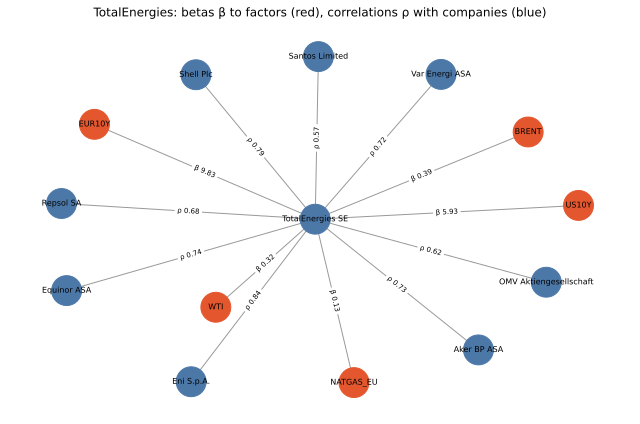

In [9]:
rows = client.read(
    """
    MATCH (company:Company {isin: $isin})
    CALL {
        WITH company
        MATCH (company)-[link:SENSITIVE_TO]->(factor:Factor)
        RETURN factor.code AS target, 'factor' AS kind, link.beta AS weight
        UNION ALL
        WITH company
        MATCH (company)-[link:CORRELATED_WITH]-(other:Company)
        RETURN other.name AS target, 'company' AS kind, link.rho AS weight
        ORDER BY weight DESC LIMIT 8
    }
    RETURN company.name AS source, target, kind, weight
    LIMIT 30
    """,
    {"isin": "FR0000120271"},
)
graph = nx.Graph()
for row in rows:
    graph.add_node(row["target"], kind=row["kind"])
    symbol = "β" if row["kind"] == "factor" else "ρ"
    graph.add_edge(row["source"], row["target"], label=f"{symbol} {row['weight']:.2f}")
colors = ["#e4572e" if graph.nodes[node].get("kind") == "factor" else "#4c78a8" for node in graph]
plt.figure(figsize=(9, 6))
layout = nx.spring_layout(graph, seed=7)
nx.draw_networkx(graph, layout, node_color=colors, node_size=900, font_size=8, edge_color="#999999")
nx.draw_networkx_edge_labels(graph, layout, nx.get_edge_attributes(graph, "label"), font_size=7)
plt.title("TotalEnergies: betas β to factors (red), correlations ρ with companies (blue)")
plt.axis("off")
plt.tight_layout()
plt.savefig("docs/img/c_subgraph_totalenergies.png", dpi=110)
plt.show()

## 5. Machine learning (C3)

Question: is a company exposed to a factor, judging only by its place in the graph? Trained on 2020-2023, tested on
2023-2026 (a period the model never sees). Exposed pairs are rare (about 14 %), so the main metric is AUC-PR,
and the baseline is "the share of the company's industry that is exposed".

In [10]:
metrics_path = Path("ml/artifacts/metrics.json")
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
print("train", metrics["windows"]["train"], "| test", metrics["windows"]["test"], "| exposed share (test):",
      metrics["exposed_share"]["test"])
display(
    pd.DataFrame(
        {
            name: {"AUC-PR": values["auc_pr"], **{f"precision@{k}": v for k, v in values["precision_at"].items()}}
            for name, values in metrics["metrics"].items()
        }
    ).T
)
display(pd.DataFrame(metrics["importances"][:5]))

train ['2020-10-25', '2023-10-24'] | test ['2023-10-25', '2026-10-23'] | exposed share (test): 0.1417


,AUC-PR,precision@50,precision@100,precision@500
baseline,0.2697,0.56,0.75,0.608
logistic,0.5721,0.88,0.94,0.948
gradient_boosting,0.5728,1.00,1.00,0.972


,feature,auc_pr_drop
0,neighbour_rate,0.3118
1,industry_rate,0.0287
2,knn_rate,0.0225
3,neighbour_peers,0.0133
4,neighbour_beta,0.0109


In [11]:
predictions = gds.predicted_exposures("FR0010208488", limit=5)  # ENGIE
display(pd.DataFrame([line.model_dump() for line in predictions or []])[
    ["company_name", "factor_code", "truth", "prob", "source"]
])

,company_name,factor_code,truth,prob,source
0,ENGIE S.A.,US10Y,prediction,0.9517,gradient_boosting-2026-10-23
1,ENGIE S.A.,EUR10Y,prediction,0.9471,gradient_boosting-2026-10-23
2,ENGIE S.A.,NATGAS_EU,prediction,0.5049,gradient_boosting-2026-10-23


`neighbour_rate` (the share of a company's correlation neighbours that are exposed) carries most of the model.
Honest limit: inside a window, the neighbours' exposure and the label come from the same prices, so the score is
probably a bit optimistic. A probability here is a ranking score, not a calibrated chance.

## 6. One question to the agent (C4 + C5)

The agent plans with typed tools (at most 6 calls), writes claims with evidence refs, and the verifier removes any
claim whose numbers, refs or truth level the trace does not support. It needs Ollama (`make llm-pull`).

In [12]:
from app.agent.graph import ShockAgent

QUESTION = "If Brent rises 20 %, what is the estimated impact on TotalEnergies?"
try:
    with urllib.request.urlopen(f"{settings.ollama_base_url}/api/tags", timeout=3):
        ollama_up = True
except OSError:
    ollama_up = False
if settings.llm_provider == "ollama" and not ollama_up:
    print("Ollama is not running at", settings.ollama_base_url, "- start it (make docker-run, make llm-pull) and rerun")
else:
    answer = ShockAgent(client).ask(QUESTION)
    print(answer.answer, "\n")
    display(pd.DataFrame([claim.model_dump() for claim in answer.claims]))
    if answer.removed_claims:
        print("removed by the verifier:")
        display(pd.DataFrame([claim.model_dump() for claim in answer.removed_claims]))
    display(pd.DataFrame([call.model_dump(exclude={"result"}) for call in answer.trace]))

TotalEnergies: 7.732 % for Brent rise 



,text,truth,evidence,reason
0,TotalEnergies: 7.732 % for Brent rise,estimate,"[Factor:BRENT, Company:FR0000120271]",None


,tool,args,result_preview,duration_ms,error
0,simulate_shock,"{'factor_code': 'BRENT', 'pct': 20, 'positions': [{'amou...","{""portfolio_impact_eur"": 77.32, ""portfolio_impact_pct"": ...",3081,None


In [13]:
client.close()
print(DISCLAIMER)

Educational and analytical tool only. Not investment advice: nothing here is a recommendation to buy or sell. Statistical estimates describe the past and do not prove causation.
